# Grover's algorithm — rounds vs. success rate

For n = 3, 4, 5 we run Grover with r = 0, 1, 2, … rounds (going well past the optimum) and compare the
measured success rate with the theory curve

$$P(r) = \sin^2\big((2r+1)\,\theta\big), \qquad \theta = \arcsin\sqrt{1/N}.$$

Too few rounds and the marked state isn't amplified enough; too many and we "overshoot" and the
probability drops again — it oscillates.

In [13]:
import os
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import AerSimulator

%run grover_core.ipynb   # loads oracle, diffuser, grover, optimal_iterations, theoretical_success, success_rate

os.makedirs("figures", exist_ok=True)

In [14]:
def measured_success(sim, n, marked, r, shots):
    qc = grover(n, marked, r)
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    return success_rate(counts, marked, shots)

In [15]:
def run_experiment(configs, shots=2048):
    sim = AerSimulator()
    results = {}
    for n, marked in configs:
        r_opt = optimal_iterations(n)
        r_max = 2 * r_opt + 2            # go well past the optimum
        rs = list(range(r_max + 1))
        rates = [measured_success(sim, n, marked, r, shots) for r in rs]
        results[(n, marked)] = (rs, rates, r_opt)

        print(f"\nn={n}, marked={marked}, optimal r={r_opt}")
        print(" r | measured | theory")
        for r, p in zip(rs, rates):
            print(f"{r:2d} |  {p:.3f}   | {theoretical_success(n, r):.3f}")
    return results

In [16]:
def plot_results(results, shots, filename="figures/fig_iterations_n3_n4_n5.png"):
    fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4), sharey=True)
    if len(results) == 1:
        axes = [axes]
    for ax, ((n, marked), (rs, rates, r_opt)) in zip(axes, results.items()):
        fine_r = [i / 20 for i in range(int(max(rs) * 20) + 1)]
        ax.plot(fine_r, [theoretical_success(n, r) for r in fine_r], "-", label="theory")
        ax.plot(rs, rates, "o", label=f"simulation ({shots} shots)")
        ax.axvline(r_opt, linestyle="--", color="gray", label="optimal r")
        ax.set_title(f"n = {n}, marked = {marked} (optimal r = {r_opt})")
        ax.set_xlabel("Grover rounds r")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("Success probability")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    print(f"\nSaved plot to {filename}")
    plt.show()


n=3, marked=101, optimal r=2
 r | measured | theory
 0 |  0.121   | 0.125
 1 |  0.778   | 0.781
 2 |  0.946   | 0.945
 3 |  0.302   | 0.330
 4 |  0.010   | 0.012
 5 |  0.552   | 0.548
 6 |  1.000   | 1.000

n=4, marked=1011, optimal r=3
 r | measured | theory
 0 |  0.074   | 0.062
 1 |  0.468   | 0.473
 2 |  0.897   | 0.908
 3 |  0.959   | 0.961
 4 |  0.593   | 0.582
 5 |  0.134   | 0.125
 6 |  0.016   | 0.020
 7 |  0.356   | 0.365
 8 |  0.841   | 0.836

n=5, marked=10010, optimal r=4
 r | measured | theory
 0 |  0.025   | 0.031
 1 |  0.270   | 0.258
 2 |  0.613   | 0.602
 3 |  0.899   | 0.897
 4 |  1.000   | 0.999
 5 |  0.864   | 0.860
 6 |  0.551   | 0.546
 7 |  0.196   | 0.210
 8 |  0.016   | 0.014
 9 |  0.055   | 0.054
10 |  0.321   | 0.310

Saved plot to figures/fig_iterations_n3_n4_n5.png


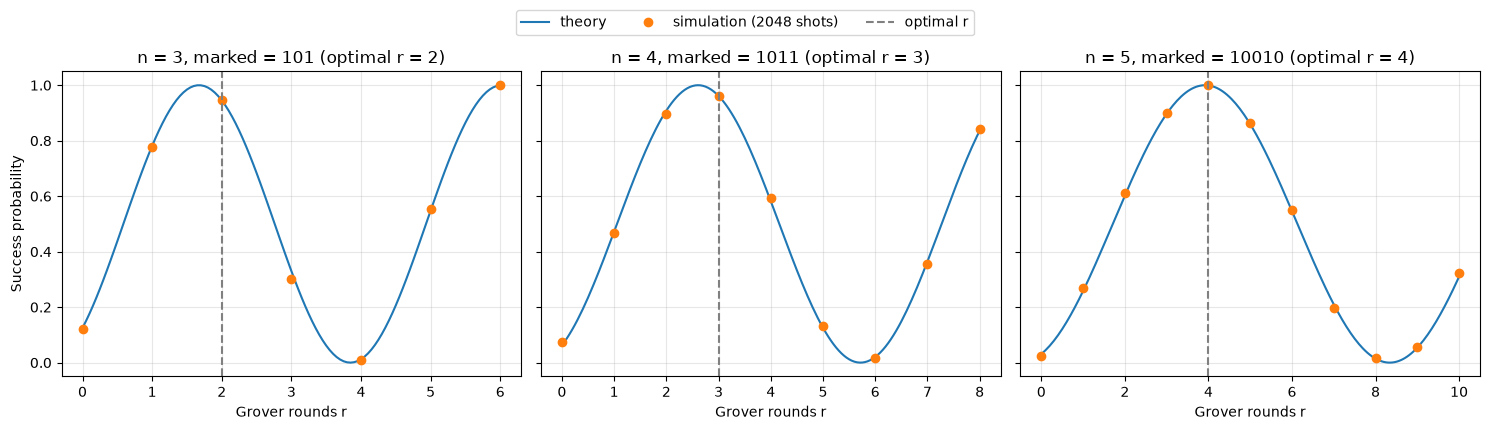

In [17]:
SHOTS = 2048
CONFIGS = [(3, "101"), (4, "1011"), (5, "10010")]
results = run_experiment(CONFIGS, shots=SHOTS)
plot_results(results, SHOTS)